In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, utils
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models, utils, callbacks, regularizers
# ----------------------------
# 1. Load & Preprocess Data
# ----------------------------
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
target   = 'AQI_Category'

In [ ]:
# 1. Compute absolute counts and relative percentages
counts  = df['AQI_Category'].value_counts().sort_index()
percent = df['AQI_Category'].value_counts(normalize=True).mul(100).round(2).sort_index()

# 2. Combine into one DataFrame
freq_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percent
})

print(freq_df)


               Count  Percentage (%)
AQI_Category                        
Good           11800            4.35
Moderate      170940           63.00
Poor           14400            5.31
Satisfactory   37263           13.73
Severe          8842            3.26
Very Poor      28081           10.35


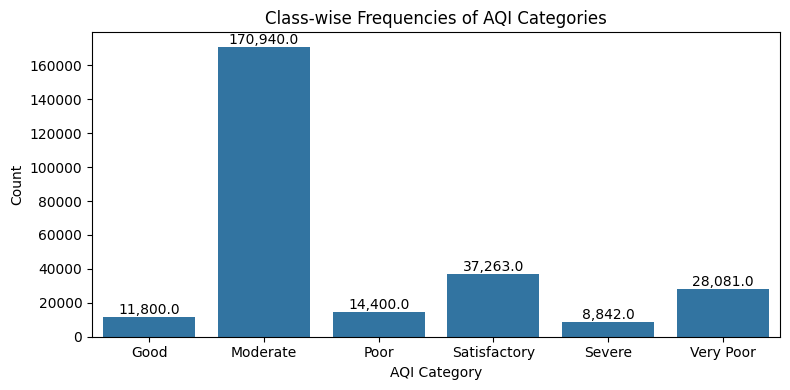

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.countplot(
    x='AQI_Category',
    data=df,
    order=freq_df.index
)
plt.title('Class-wise Frequencies of AQI Categories')
plt.xlabel('AQI Category')
plt.ylabel('Count')

# Annotate each bar with its height
for p in plt.gca().patches:
    plt.gca().annotate(
        f'{p.get_height():,}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center', va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [ ]:
import random
import time

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# --------------------------------
# 2. Encode target
# --------------------------------
le = LabelEncoder()
df['AQI_Enc'] = le.fit_transform(df[target])

X = df[features].values
y = df['AQI_Enc'].values

# --------------------------------
# 3. Stratified 80/20 train-test split
# --------------------------------
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------
# 4. Stratified train-validation split
# --------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)

# --------------------------------
# 5. Normalize without data leakage
# --------------------------------
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# --------------------------------
# 6. Confirm class-wise distribution
# --------------------------------
split_df = pd.DataFrame({
    'Total': pd.Series(y).value_counts(),
    'Train': pd.Series(y_train).value_counts(),
    'Validation': pd.Series(y_val).value_counts(),
    'Test': pd.Series(y_test).value_counts()
}).fillna(0).astype(int)

split_df.index = le.inverse_transform(
    split_df.index.to_numpy(dtype=int)
)

split_df['Train %'] = (
    split_df['Train'] / split_df['Total'] * 100
).round(2)

split_df['Validation %'] = (
    split_df['Validation'] / split_df['Total'] * 100
).round(2)

split_df['Test %'] = (
    split_df['Test'] / split_df['Total'] * 100
).round(2)

print(split_df)

               Total   Train  Validation   Test  Train %  Validation %  Test %
Moderate      170940  116238       20513  34189     68.0          12.0    20.0
Satisfactory   37263   25339        4471   7453     68.0          12.0    20.0
Very Poor      28081   19095        3370   5616     68.0          12.0    20.0
Poor           14400    9792        1728   2880     68.0          12.0    20.0
Good           11800    8024        1416   2360     68.0          12.0    20.0
Severe          8842    6013        1061   1768     68.0          12.0    20.0


In [ ]:
# --------------------------------
# 1. One-hot encode targets
# --------------------------------
num_classes = len(le.classes_)

y_train_cat = utils.to_categorical(y_train, num_classes)
y_val_cat = utils.to_categorical(y_val, num_classes)
y_test_cat = utils.to_categorical(y_test, num_classes)

# --------------------------------
# 2. Reshape input for LSTM
# --------------------------------
X_train_reshaped = X_train.reshape(
    (X_train.shape[0], 1, X_train.shape[1])
)

X_val_reshaped = X_val.reshape(
    (X_val.shape[0], 1, X_val.shape[1])
)

X_test_reshaped = X_test.reshape(
    (X_test.shape[0], 1, X_test.shape[1])
)

# --------------------------------
# 3. Define LSTM Model
# --------------------------------
model = models.Sequential([
    layers.Input(shape=(1, len(features))),

    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.3),

    layers.LSTM(32),
    layers.Dropout(0.2),

    layers.Dense(32, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# --------------------------------
# 4. Callbacks
# --------------------------------
es = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

rlr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3
)

# --------------------------------
# 5. Train LSTM
# --------------------------------
start_time = time.perf_counter()

history = model.fit(
    X_train_reshaped,
    y_train_cat,

    validation_data=(
        X_val_reshaped,
        y_val_cat
    ),

    epochs=50,
    batch_size=32,
    verbose=2,
    callbacks=[es, rlr]
)

training_time = time.perf_counter() - start_time

print(f"Training Time: {training_time:.2f} seconds")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 64)          │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,846 (124.40 KB)

 Trainable params: 31,846 (124.40 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
5766/5766 - 26s - 4ms/step - accuracy: 0.8463 - loss: 0.4019 - val_accuracy: 0.9450 - val_loss: 0.1558 - learning_rate: 0.0010
Epoch 2/50
5766/5766 - 22s - 4ms/step - accuracy: 0.9227 - loss: 0.1861 - val_accuracy: 0.9555 - val_loss: 0.1290 - learning_rate: 0.0010
Epoch 3/50
5766/5766 - 22s - 4ms/step - accuracy: 0.9342 - loss: 0.1602 - val_accuracy: 0.9628 - val_loss: 0.1037 - learning_rate: 0.0010
Epoch 4/50
5766/5766 - 22s - 4ms/step - accuracy: 0.9432 - loss: 0.1339 - val_accuracy: 0.9715 - val_loss: 0.0792 - learning_rate: 0.0010
Epoch 5/50
5766/5766 - 21s - 4ms/step - accuracy: 0.9506 - loss: 0.1167 - val_accuracy: 0.9746 - val_loss: 0.0689 - learning_rate: 0.0010
Epoch 6/50
5766/5766 - 21s - 4ms/step - accuracy: 0.9547 - loss: 0.1081 - val_accuracy: 0.9758 - val_loss: 0.0632 - learning_rate: 0.0010
Epoch 7/50
5766/5766 - 21s - 4ms/step - accuracy: 0.9575 - loss: 0.1017 - val_accuracy: 0.9796 - val_loss: 0.0596 - learning_rate: 0.0010
Epoch 8/50
5766/5766 - 21s - 4ms/s

# new


=== LSTM CLASS-WISE AP ===
Model AQI Category  Support  Average Precision
 LSTM         Good     2360           0.996182
 LSTM     Moderate    34189           0.999973
 LSTM         Poor     2880           0.999442
 LSTM Satisfactory     7453           0.998626
 LSTM       Severe     1768           0.999468
 LSTM    Very Poor     5616           0.999844

=== LSTM OVERALL AP ===
Macro AP    : 0.998923
Weighted AP : 0.999565
Micro AP    : 0.999785

=== LSTM OVERALL RESULTS ===
Model Dataset  Train Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Macro AP  Weighted AP  Micro AP  Training Time (s)  Inference Time (s)
 LSTM   Merge        0.993832       0.993016          0.98407      0.989329  0.986676     0.993034  0.998923     0.999565  0.999785        1078.137701            3.691448

=== LSTM CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        Good     0.9669    0.9775    0.9722      2360
    Moderate     0.9989    0.996

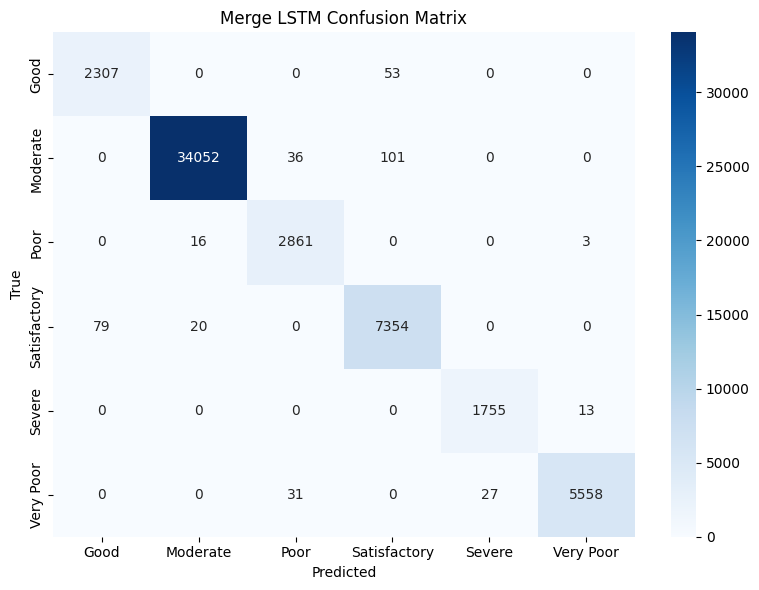

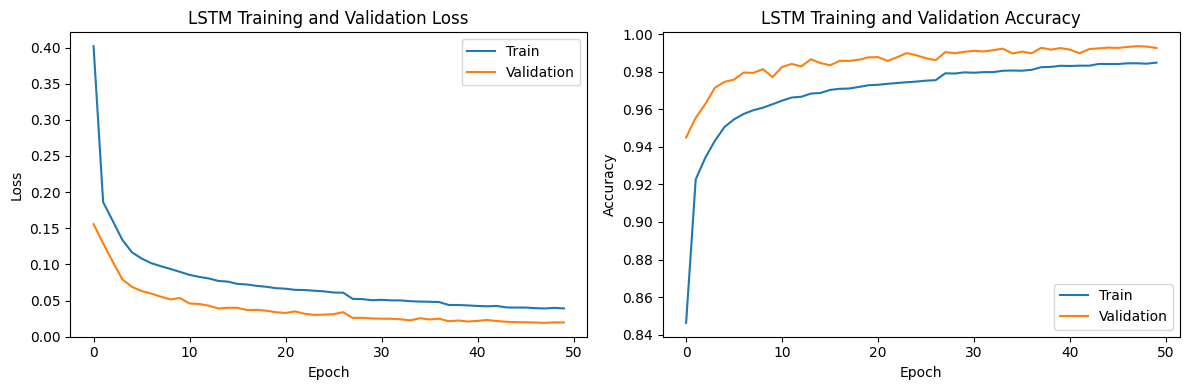

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

# --------------------------------
# 1. Evaluate train and test
# --------------------------------
train_loss, train_acc = model.evaluate(
    X_train_reshaped,
    y_train_cat,
    verbose=0
)

test_loss, test_acc = model.evaluate(
    X_test_reshaped,
    y_test_cat,
    verbose=0
)

# --------------------------------
# 2. Predictions and inference time
# --------------------------------
start_time = time.perf_counter()

y_pred_prob = model.predict(
    X_test_reshaped,
    verbose=0
)

inference_time = time.perf_counter() - start_time

y_pred = np.argmax(y_pred_prob, axis=1)

# --------------------------------
# 3. Evaluation metrics
# --------------------------------

# ============================================================
# STEP 3: EVALUATION METRICS + AVERAGE PRECISION (AP)
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

acc = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# MULTICLASS AVERAGE PRECISION
# ------------------------------------------------------------

y_true_onehot = np.asarray(y_test_cat)
y_prob = np.asarray(y_pred_prob)

assert y_true_onehot.shape == y_prob.shape, (
    "One-hot labels and probabilities must have "
    "the same shape."
)

assert y_prob.shape[1] == len(le.classes_), (
    "Number of output probabilities must match "
    "the number of AQI classes."
)

# Macro AP
macro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="macro"
)

# Weighted AP
weighted_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="weighted"
)

# Micro AP
micro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="micro"
)

# ------------------------------------------------------------
# CLASS-WISE AP FOR ALL SIX AQI CATEGORIES
# ------------------------------------------------------------

classwise_ap_results = []

for i, class_name in enumerate(le.classes_):

    class_ap = average_precision_score(
        y_true_onehot[:, i],
        y_prob[:, i]
    )

    classwise_ap_results.append({
        "Model": "LSTM",
        "AQI Category": class_name,
        "Support": int(y_true_onehot[:, i].sum()),
        "Average Precision": class_ap
    })

lstm_classwise_ap_df = pd.DataFrame(
    classwise_ap_results
)

print("\n=== LSTM CLASS-WISE AP ===")

print(
    lstm_classwise_ap_df.round(6).to_string(
        index=False
    )
)

print("\n=== LSTM OVERALL AP ===")
print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")


# --------------------------------
# 4. Results table
# --------------------------------

# ============================================================
# STEP 4: RESULTS TABLE + SAVE TO GOOGLE DRIVE
# ============================================================

from pathlib import Path

results_df = pd.DataFrame([{
    "Model": "LSTM",
    "Dataset": "Merge",
    "Train Accuracy": train_acc,
    "Test Accuracy": acc,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1,
    "Macro AP": macro_ap,
    "Weighted AP": weighted_ap,
    "Micro AP": micro_ap,
    "Training Time (s)": training_time,
    "Inference Time (s)": inference_time
}])

print("\n=== LSTM OVERALL RESULTS ===")
print(results_df.round(6).to_string(index=False))

print("\n=== LSTM CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# SAVE RESULTS TO REQUESTED GOOGLE DRIVE DIRECTORY
# ============================================================

# Mount Drive first if using Google Colab:
# from google.colab import drive
# drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/My work/"
    "Air Quality Project/Paper 1(External Data)/New/"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save overall metrics
results_df.to_csv(
    SAVE_DIR / "LSTM_Overall_Results_AP.csv",
    index=False
)

# Save individual class AP scores
lstm_classwise_ap_df.to_csv(
    SAVE_DIR / "LSTM_Classwise_AP.csv",
    index=False
)

print("\nResults saved to:", SAVE_DIR)

# --------------------------------
# 5. Confusion matrix
# --------------------------------
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Merge LSTM Confusion Matrix')
plt.tight_layout()
plt.show()

# --------------------------------
# 6. Training curves
# --------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['loss'], label='Train')
ax1.plot(history.history['val_loss'], label='Validation')
ax1.set_title('LSTM Training and Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train')
ax2.plot(history.history['val_accuracy'], label='Validation')
ax2.set_title('LSTM Training and Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_2361/2893006780.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


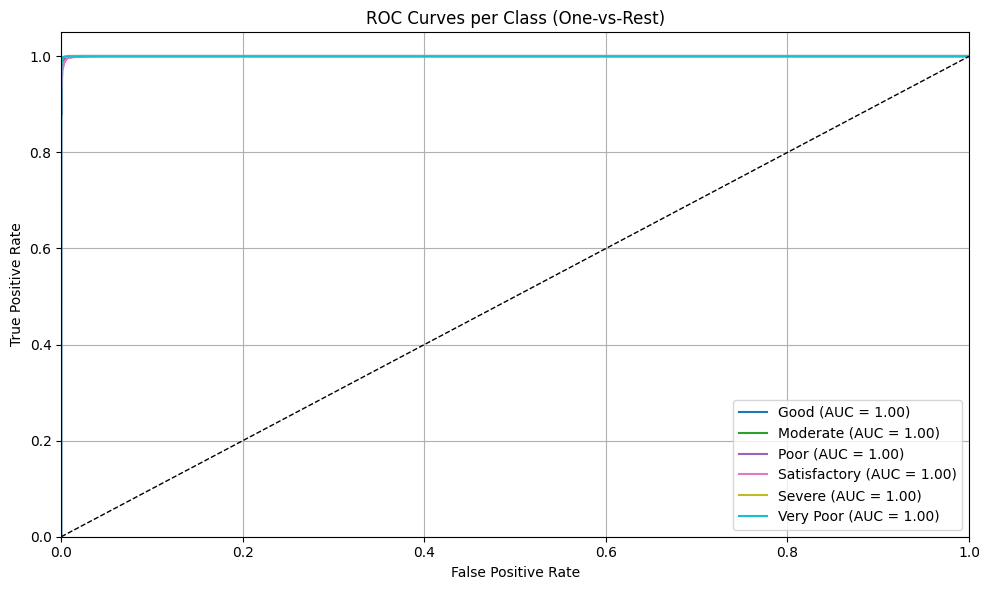

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize the true labels
y_test_bin = label_binarize(y_test, classes=range(num_classes))  # Shape: (n_samples, n_classes)

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 6))
colors = plt.cm.get_cmap("tab10", num_classes)

for i in range(num_classes):
    plt.plot(fpr[i], tpr[i],
             label=f'{le.classes_[i]} (AUC = {roc_auc[i]:.2f})',
             color=colors(i))

# Random baseline
plt.plot([0, 1], [0, 1], 'k--', lw=1)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves per Class (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


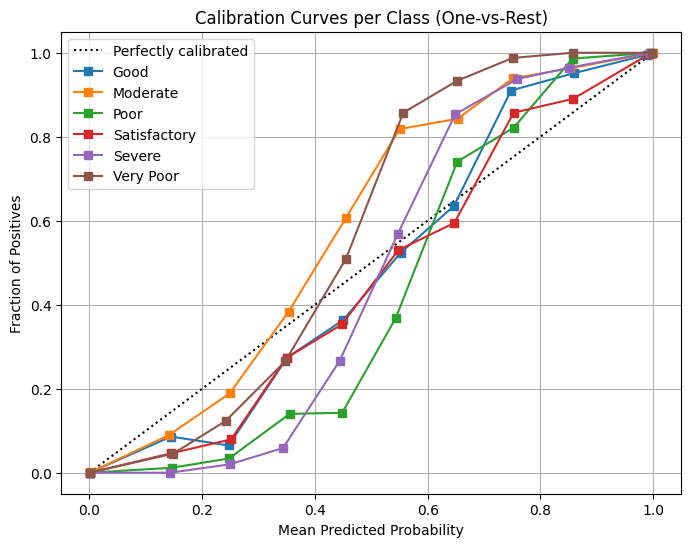

In [ ]:
from sklearn.calibration import CalibrationDisplay



plt.figure(figsize=(8, 6))

for i, class_name in enumerate(le.classes_):
    CalibrationDisplay.from_predictions(
        y_test_bin[:, i],
        y_pred_prob[:, i],
        n_bins=10,
        name=f'{class_name}',
        ax=plt.gca() # Plot all curves on the same axes
    )

plt.title('Calibration Curves per Class (One-vs-Rest)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


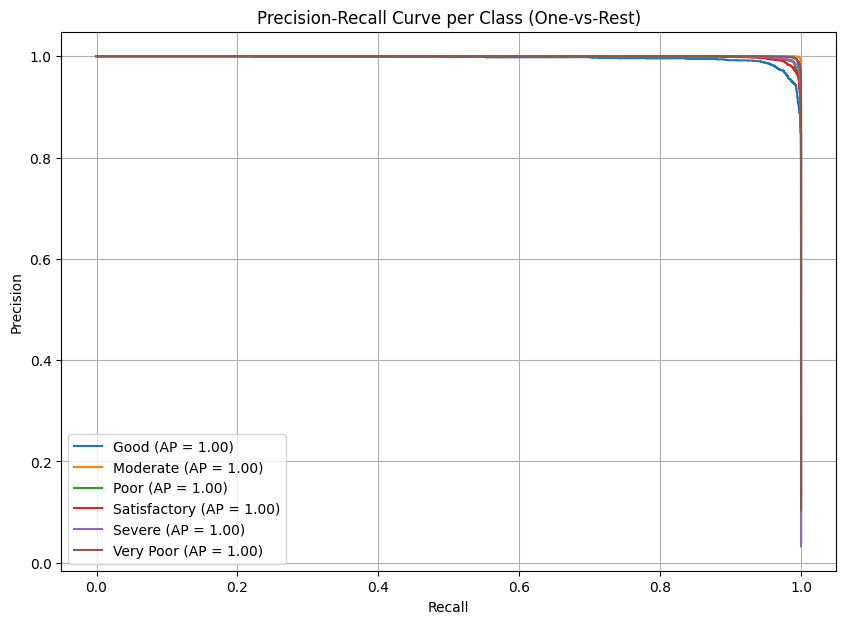

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(le.classes_):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_pred_prob[:, i])
    ap_score = average_precision_score(y_test_bin[:, i], y_pred_prob[:, i])
    plt.plot(recall, precision, label=f'{class_name} (AP = {ap_score:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve per Class (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()